Folder hasil: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order
Folder grafik: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi


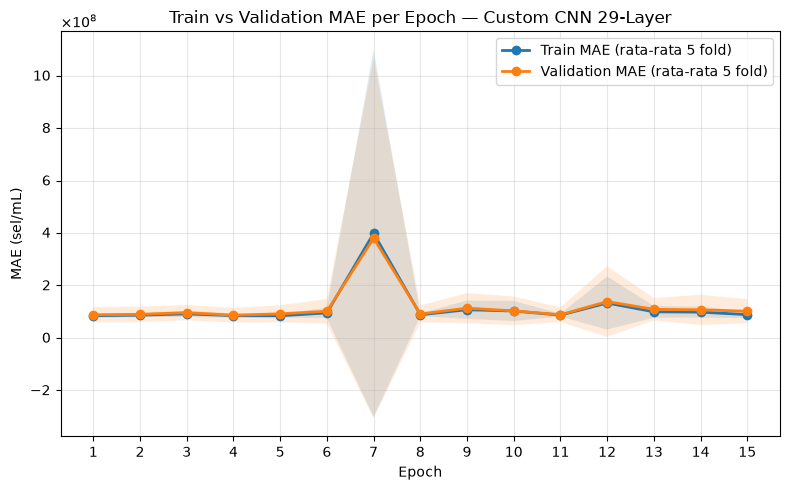

Grafik MAE per epoch disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\mae_epoch_custom_cnn_29_layer.png


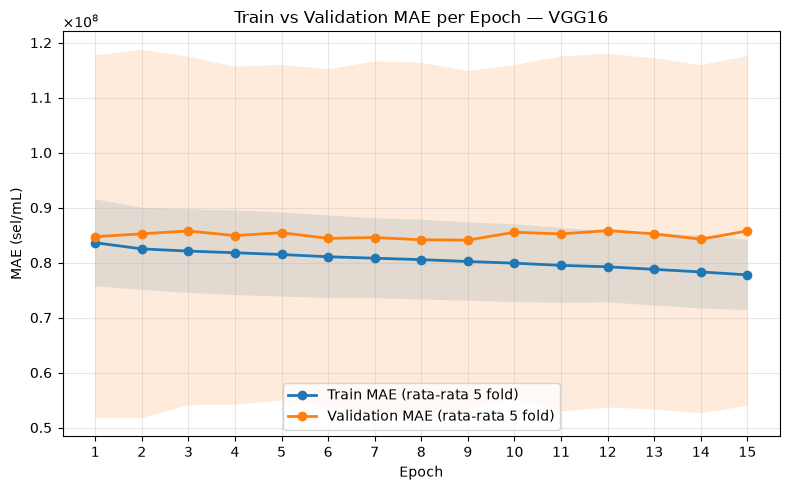

Grafik MAE per epoch disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\mae_epoch_vgg16.png


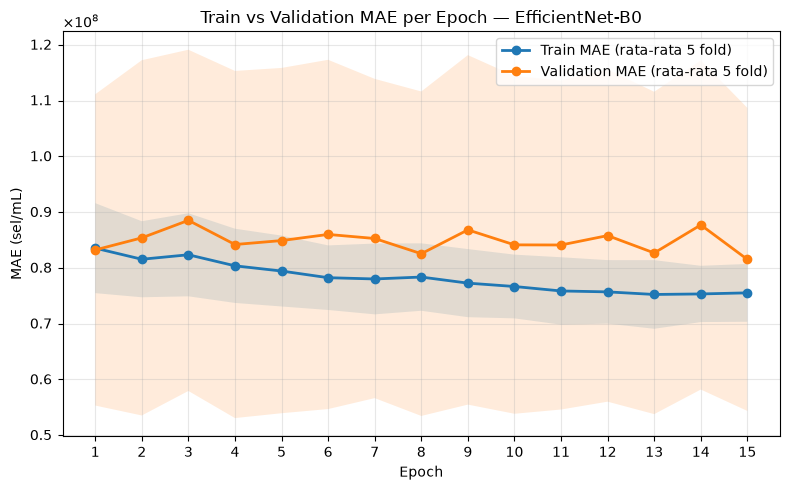

Grafik MAE per epoch disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\mae_epoch_efficientnet_b0.png


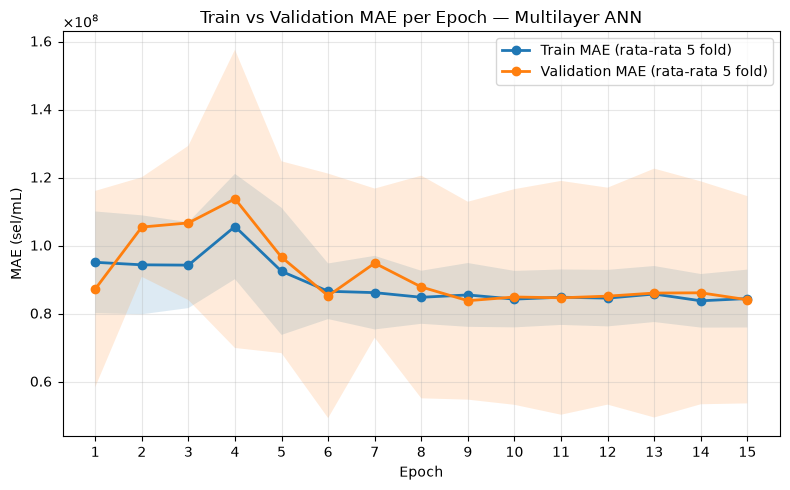

Grafik MAE per epoch disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\mae_epoch_multilayer_ann.png


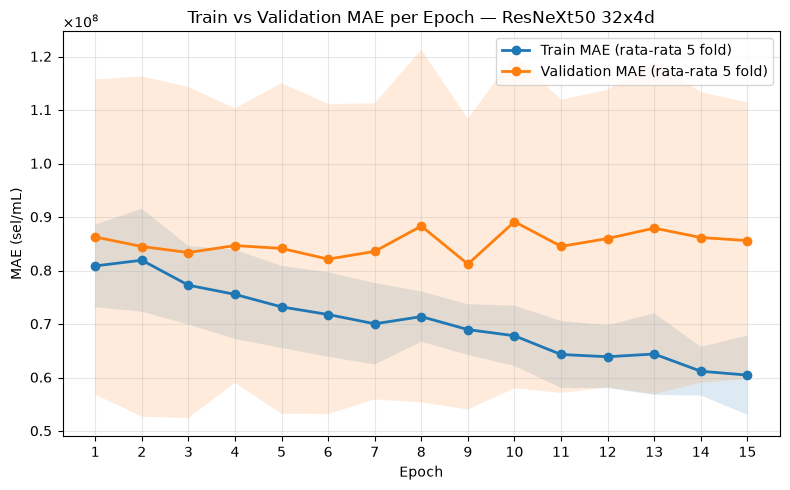

Grafik MAE per epoch disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\mae_epoch_resnext50_32x4d.png


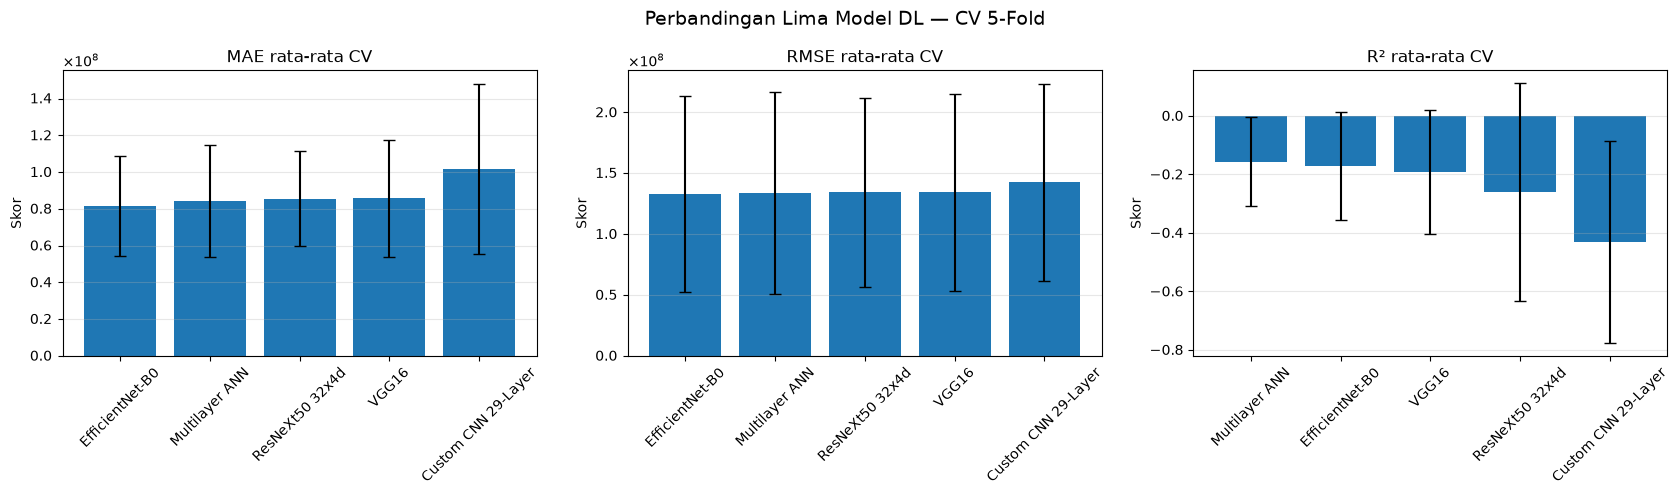

Grafik perbandingan CV disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\perbandingan_metrik_cv.png


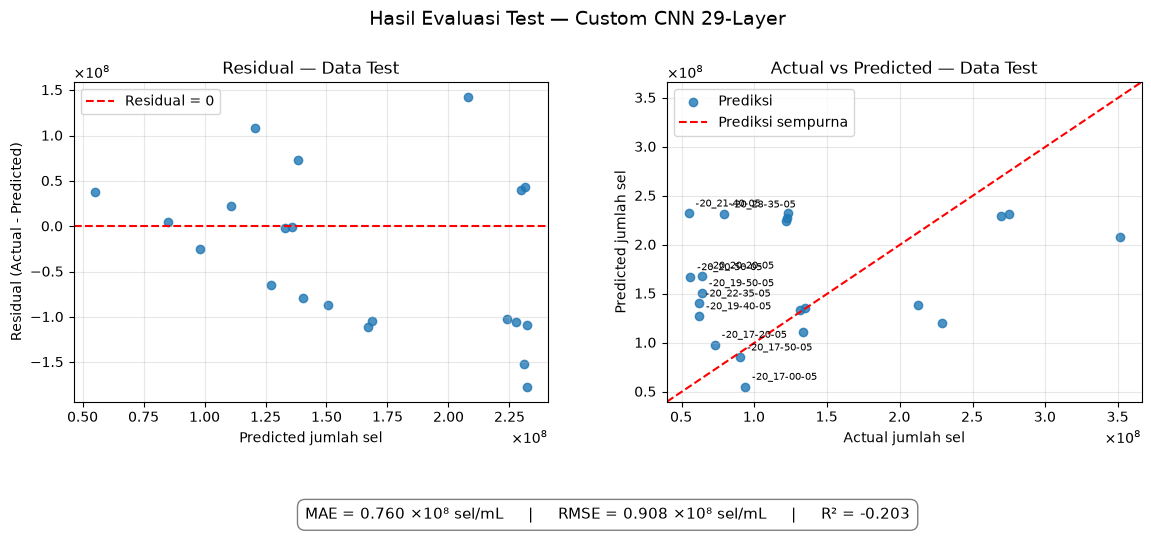

Grafik evaluasi test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\evaluasi_test_custom_cnn_29_layer.png


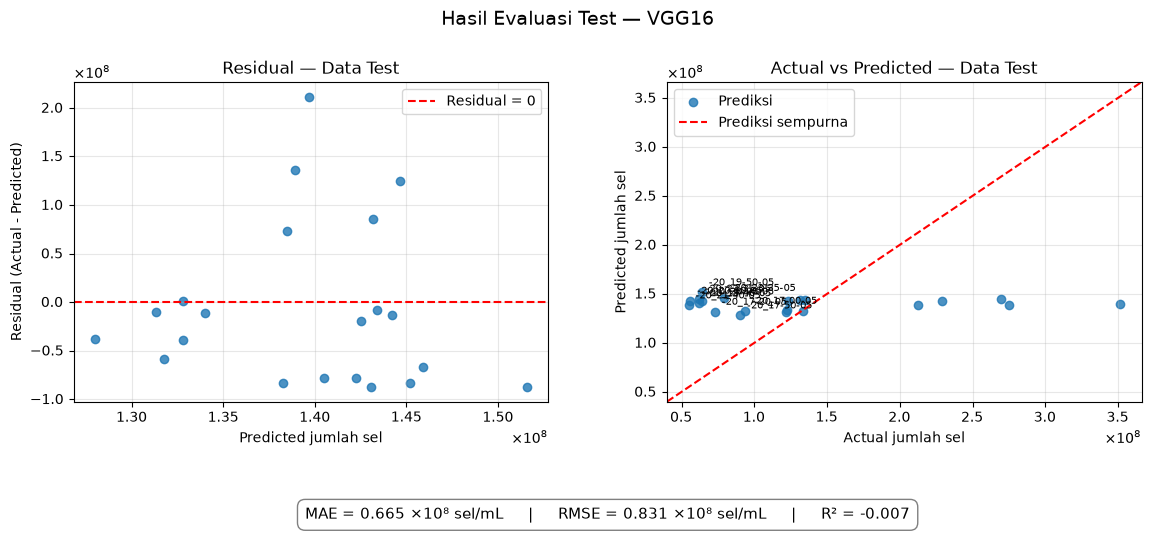

Grafik evaluasi test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\evaluasi_test_vgg16.png


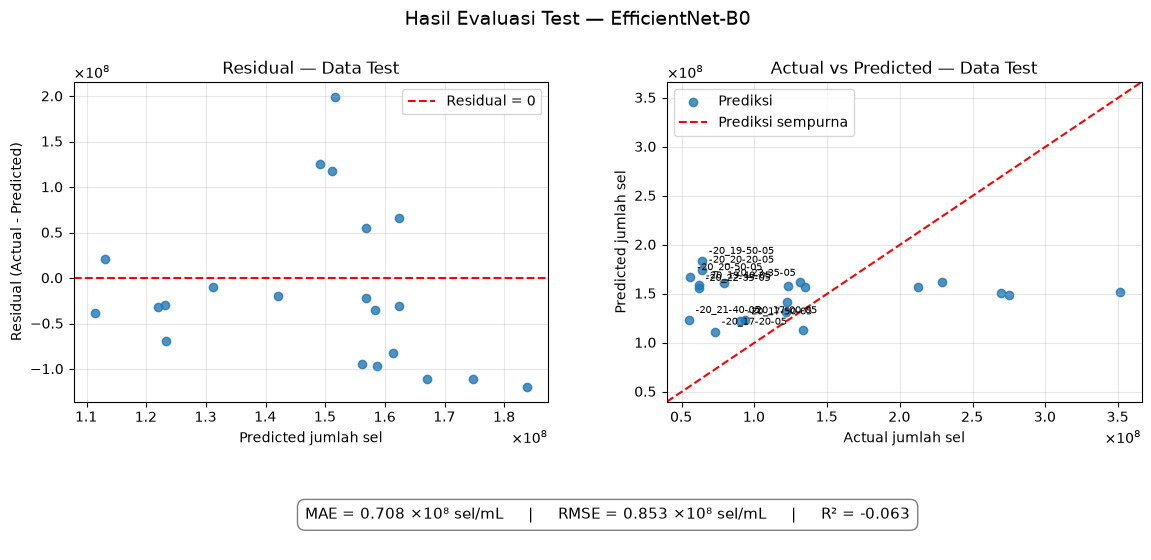

Grafik evaluasi test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\evaluasi_test_efficientnet_b0.png


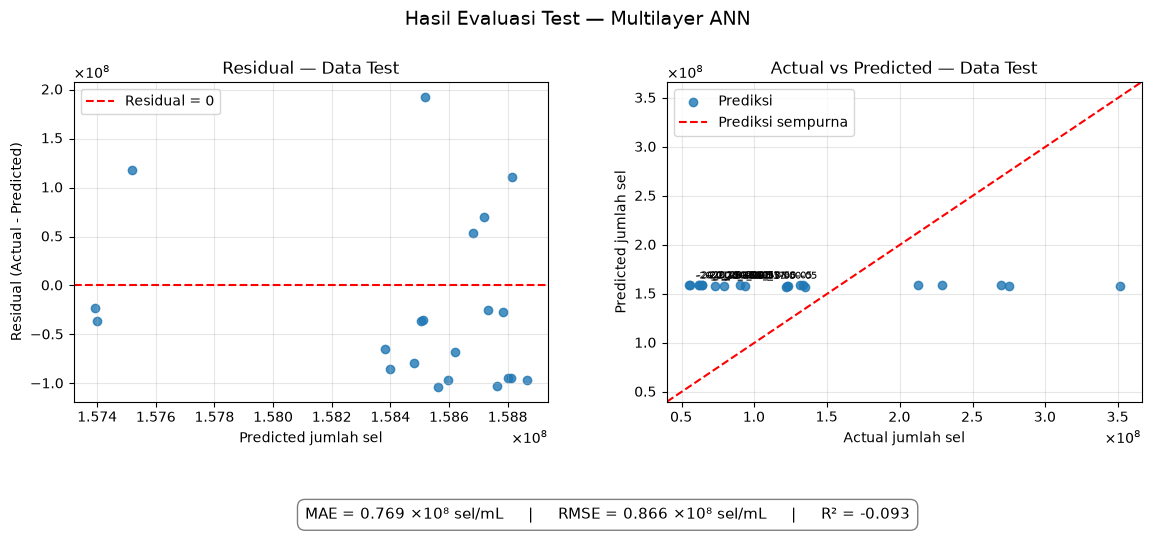

Grafik evaluasi test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\evaluasi_test_multilayer_ann.png


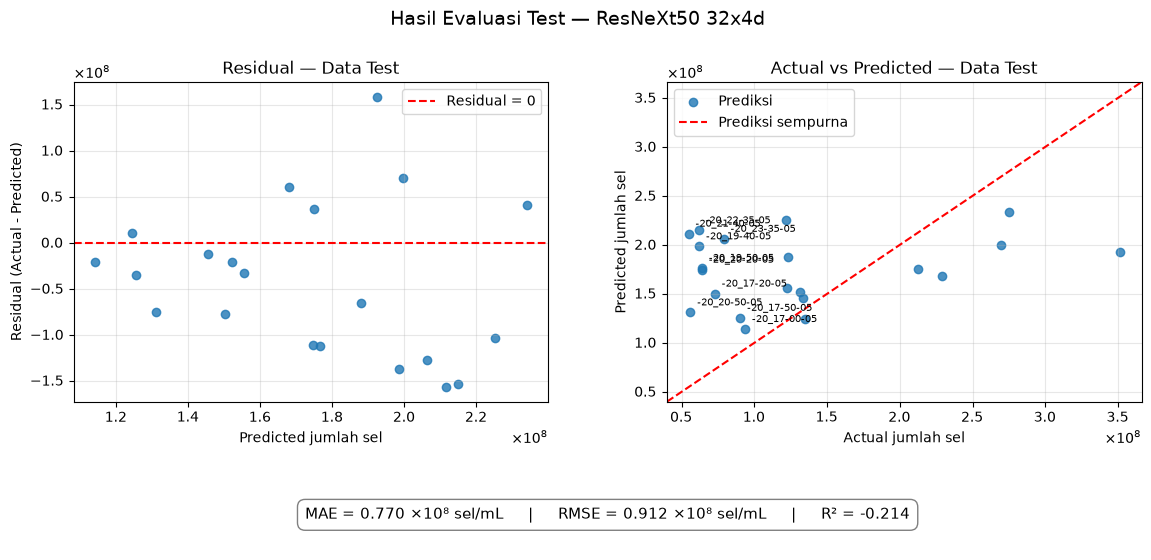

Grafik evaluasi test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\evaluasi_test_resnext50_32x4d.png


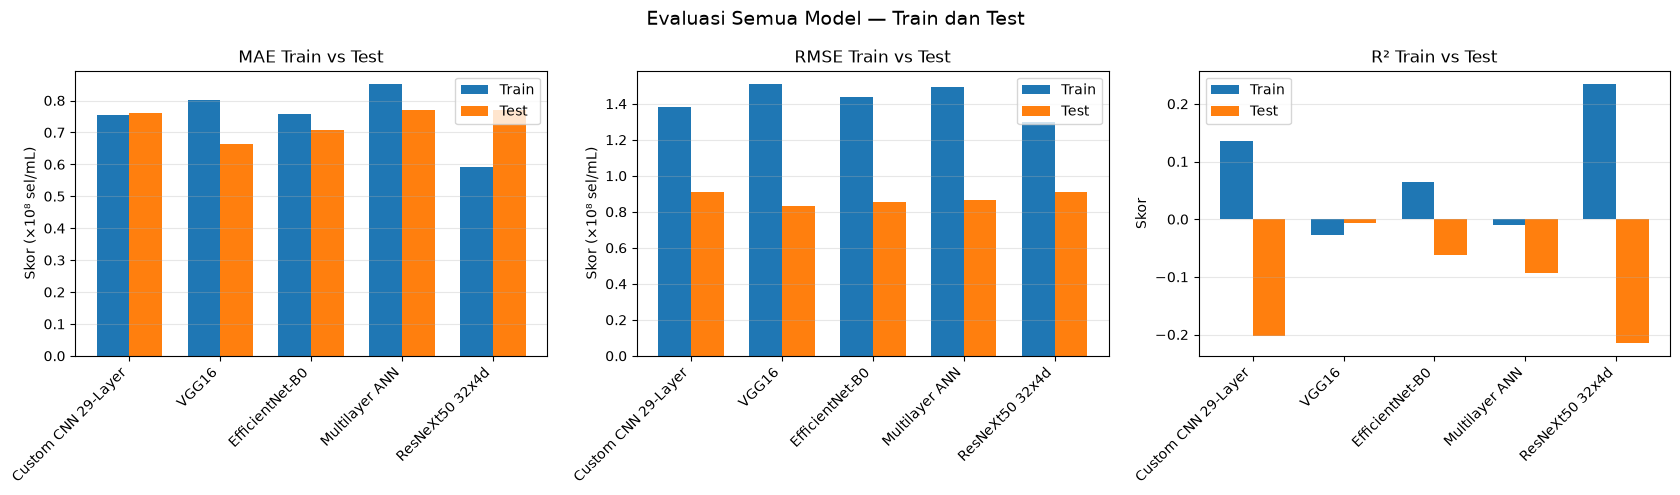

Grafik train-test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi\perbandingan_train_test.png


,Model,MAE,RMSE,R2
0,Custom CNN 29-Layer,7.599266e+07,9.080939e+07,-0.203
1,VGG16,6.650568e+07,8.308970e+07,-0.007
2,EfficientNet-B0,7.084218e+07,8.534054e+07,-0.063
3,Multilayer ANN,7.691226e+07,8.656766e+07,-0.093
4,ResNeXt50 32x4d,7.704304e+07,9.123665e+07,-0.214


Metrik test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\dl_test_metrics_visualization.csv
Semua grafik disimpan di: D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order\visualisasi


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from matplotlib.ticker import ScalarFormatter
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 1. Lokasi CSV hasil training
# ============================================================

OUTPUT_DIR = Path(r"D:\00 Kuliah\TA\Experiment\Model\5 DL\Hasil\Random Order")
PLOT_DIR = OUTPUT_DIR / "visualisasi"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

CV_EPOCH_FILE = OUTPUT_DIR / "dl_cv_loss_mean_per_epoch.csv"
CV_SUMMARY_FILE = OUTPUT_DIR / "dl_cv_model_summary.csv"
TRAIN_TEST_FILE = OUTPUT_DIR / "dl_final_metrics_train_test.csv"
TEST_PREDICTIONS_FILE = OUTPUT_DIR / "dl_test_predictions_all_models.csv"
TEST_METRICS_FILE = OUTPUT_DIR / "dl_test_metrics_all_models.csv"

files_required = [
    CV_EPOCH_FILE,
    CV_SUMMARY_FILE,
    TRAIN_TEST_FILE,
    TEST_PREDICTIONS_FILE,
    TEST_METRICS_FILE,
]

for file_path in files_required:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"CSV hasil tidak ditemukan: {file_path}\n"
            "Pastikan training sudah selesai dan nama/path file sesuai."
        )

print(f"Folder hasil: {OUTPUT_DIR}")
print(f"Folder grafik: {PLOT_DIR}")


# ============================================================
# 2. Baca CSV hasil
# ============================================================

cv_epoch = pd.read_csv(CV_EPOCH_FILE, encoding="utf-8-sig")
cv_summary = pd.read_csv(CV_SUMMARY_FILE, encoding="utf-8-sig")
train_test = pd.read_csv(TRAIN_TEST_FILE, encoding="utf-8-sig")
test_predictions = pd.read_csv(TEST_PREDICTIONS_FILE, encoding="utf-8-sig")
test_metrics_saved = pd.read_csv(TEST_METRICS_FILE, encoding="utf-8-sig")

model_names = [
    "Custom CNN 29-Layer",
    "VGG16",
    "EfficientNet-B0",
    "Multilayer ANN",
    "ResNeXt50 32x4d",
]


def safe_model_name(name):
    """Bentuk nama model yang digunakan sebagai suffix kolom CSV."""
    return name.lower().replace(" ", "_").replace("-", "_")


# Validasi kolom yang dibutuhkan.
required_cv_epoch = {
    "Model",
    "epoch",
    "train_mae_mean",
    "validation_mae_mean",
}
required_cv_summary = {
    "Model",
    "MAE_mean",
    "MAE_std",
    "RMSE_mean",
    "RMSE_std",
    "R2_mean",
    "R2_std",
}
required_train_test = {"Model", "Data", "MAE", "RMSE", "R2"}
required_test_predictions = {"Nama_Gambar", "actual"}
required_test_metrics = {"Model", "MAE", "RMSE", "R2"}

for data, required, label in [
    (cv_epoch, required_cv_epoch, CV_EPOCH_FILE.name),
    (cv_summary, required_cv_summary, CV_SUMMARY_FILE.name),
    (train_test, required_train_test, TRAIN_TEST_FILE.name),
    (test_predictions, required_test_predictions, TEST_PREDICTIONS_FILE.name),
    (test_metrics_saved, required_test_metrics, TEST_METRICS_FILE.name),
]:
    missing_columns = required - set(data.columns)
    if missing_columns:
        raise KeyError(
            f"Kolom {sorted(missing_columns)} tidak ditemukan di {label}."
        )

missing_prediction_columns = [
    f"predicted_{safe_model_name(name)}"
    for name in model_names
    if f"predicted_{safe_model_name(name)}" not in test_predictions.columns
]
if missing_prediction_columns:
    raise KeyError(
        "Kolom prediksi model tidak ditemukan: "
        f"{missing_prediction_columns}"
    )

actual = pd.to_numeric(
    test_predictions["actual"],
    errors="coerce",
).to_numpy(dtype=float)

if not np.isfinite(actual).all():
    raise ValueError("Kolom actual pada CSV prediksi test tidak valid.")

if len(actual) < 2:
    raise ValueError("Test set harus memiliki minimal dua sampel.")


# ============================================================
# 3. Fungsi format sumbu jumlah sel sebagai ×10⁸
# ============================================================

def format_axis_1e8(axis, which="both"):
    """Paksa sumbu menampilkan notasi ilmiah dengan faktor 10^8."""
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((8, 8))

    if which in ("x", "both"):
        axis.xaxis.set_major_formatter(formatter)
    if which in ("y", "both"):
        axis.yaxis.set_major_formatter(formatter)


# ============================================================
# 4. Grafik MAE train dan validation per epoch
#    Rata-rata dari 5 fold; satu grafik per model
# ============================================================

for model_name in model_names:
    curve = cv_epoch.loc[cv_epoch["Model"] == model_name].sort_values("epoch")

    if curve.empty:
        raise ValueError(
            f"Tidak ada riwayat epoch untuk model {model_name} "
            f"di {CV_EPOCH_FILE.name}."
        )

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        curve["epoch"],
        curve["train_mae_mean"],
        marker="o",
        linewidth=2,
        label="Train MAE (rata-rata 5 fold)",
    )
    ax.plot(
        curve["epoch"],
        curve["validation_mae_mean"],
        marker="o",
        linewidth=2,
        label="Validation MAE (rata-rata 5 fold)",
    )

    # Tambahkan area variasi antarfold jika kolom standar deviasi tersedia.
    if "train_mae_std" in curve.columns:
        train_std = curve["train_mae_std"].fillna(0).to_numpy()
        train_mean = curve["train_mae_mean"].to_numpy()
        ax.fill_between(
            curve["epoch"],
            train_mean - train_std,
            train_mean + train_std,
            alpha=0.15,
        )

    if "validation_mae_std" in curve.columns:
        validation_std = curve["validation_mae_std"].fillna(0).to_numpy()
        validation_mean = curve["validation_mae_mean"].to_numpy()
        ax.fill_between(
            curve["epoch"],
            validation_mean - validation_std,
            validation_mean + validation_std,
            alpha=0.15,
        )

    format_axis_1e8(ax, which="y")
    ax.set_title(f"Train vs Validation MAE per Epoch — {model_name}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE (sel/mL)")
    ax.set_xticks(curve["epoch"].astype(int))
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    filename = safe_model_name(model_name)
    output_path = PLOT_DIR / f"mae_epoch_{filename}.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Grafik MAE per epoch disimpan: {output_path}")


# ============================================================
# 5. Grafik perbandingan skor CV kelima model
# ============================================================

cv_plot_specs = [
    ("MAE_mean", "MAE_std", "MAE rata-rata CV", True),
    ("RMSE_mean", "RMSE_std", "RMSE rata-rata CV", True),
    ("R2_mean", "R2_std", "R² rata-rata CV", False),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (mean_col, std_col, title, ascending) in zip(
    axes,
    cv_plot_specs,
):
    plot_data = cv_summary.sort_values(mean_col, ascending=ascending)

    ax.bar(
        plot_data["Model"],
        plot_data[mean_col],
        yerr=plot_data[std_col],
        capsize=4,
    )

    # MAE dan RMSE dalam satuan jumlah sel; tampilkan ringkas sebagai ×10⁸.
    if mean_col in ("MAE_mean", "RMSE_mean"):
        format_axis_1e8(ax, which="y")

    ax.set_title(title)
    ax.set_ylabel("Skor")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Perbandingan Lima Model DL — CV 5-Fold", fontsize=14)
fig.tight_layout()

cv_plot_path = PLOT_DIR / "perbandingan_metrik_cv.png"
fig.savefig(cv_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Grafik perbandingan CV disimpan: {cv_plot_path}")


# ============================================================
# 6. Grafik evaluasi test: satu gambar per model
#    Residual | Actual vs Predicted; metrik di bawah plot
# ============================================================

test_metrics_rows = []

for model_name in model_names:
    prediction_column = f"predicted_{safe_model_name(model_name)}"
    predicted = pd.to_numeric(
        test_predictions[prediction_column],
        errors="coerce",
    ).to_numpy(dtype=float)

    if not np.isfinite(predicted).all():
        raise ValueError(
            f"Kolom {prediction_column} memiliki nilai kosong/tidak valid."
        )

    residual = actual - predicted
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    test_metrics_rows.append(
        {
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
        }
    )

    # Batas otomatis mencakup seluruh actual dan predicted,
    # termasuk nilai actual di bawah 1e8.
    min_value = min(actual.min(), predicted.min())
    max_value = max(actual.max(), predicted.max())
    padding = max((max_value - min_value) * 0.05, 1.0)
    lower = min_value - padding
    upper = max_value + padding

    fig = plt.figure(figsize=(12, 6))
    grid = fig.add_gridspec(
        2,
        2,
        height_ratios=[1.0, 0.22],
        hspace=0.4,
        wspace=0.25,
    )

    ax_residual = fig.add_subplot(grid[0, 0])
    ax_actual_predicted = fig.add_subplot(grid[0, 1])
    ax_metrics = fig.add_subplot(grid[1, :])
    ax_metrics.axis("off")

    # Residual plot.
    ax_residual.scatter(predicted, residual, alpha=0.8)
    ax_residual.axhline(
        0,
        color="red",
        linestyle="--",
        label="Residual = 0",
    )
    ax_residual.set_title("Residual — Data Test")
    ax_residual.set_xlabel("Predicted jumlah sel")
    ax_residual.set_ylabel("Residual (Actual - Predicted)")
    format_axis_1e8(ax_residual, which="both")
    ax_residual.legend()
    ax_residual.grid(True, alpha=0.3)

    # Actual vs Predicted plot.
    ax_actual_predicted.scatter(actual, predicted, alpha=0.8, label="Prediksi")
    ax_actual_predicted.plot(
        [lower, upper],
        [lower, upper],
        color="red",
        linestyle="--",
        label="Prediksi sempurna",
    )
    ax_actual_predicted.set_xlim(lower, upper)
    ax_actual_predicted.set_ylim(lower, upper)
    ax_actual_predicted.set_title("Actual vs Predicted — Data Test")
    ax_actual_predicted.set_xlabel("Actual jumlah sel")
    ax_actual_predicted.set_ylabel("Predicted jumlah sel")
    format_axis_1e8(ax_actual_predicted, which="both")
    ax_actual_predicted.legend()
    ax_actual_predicted.grid(True, alpha=0.3)

    # Tandai actual di bawah 100 juta agar titiknya mudah dikenali.
    if "Nama_Gambar" in test_predictions.columns:
        low_indices = np.flatnonzero(actual < 100_000_000)
        for index in low_indices:
            image_name = str(test_predictions["Nama_Gambar"].iloc[index])
            short_name = Path(image_name).stem[-12:]
            ax_actual_predicted.annotate(
                short_name,
                (actual[index], predicted[index]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=7,
            )

    # Metrik diletakkan di bawah kedua plot, terpusat.
    ax_metrics.text(
        0.5,
        0.5,
        f"MAE = {mae / 1e8:.3f} ×10⁸ sel/mL"
        f"     |     RMSE = {rmse / 1e8:.3f} ×10⁸ sel/mL"
        f"     |     R² = {r2:.3f}",
        ha="center",
        va="center",
        fontsize=11,
        transform=ax_metrics.transAxes,
        bbox={
            "boxstyle": "round,pad=0.5",
            "facecolor": "white",
            "edgecolor": "gray",
        },
    )

    fig.suptitle(f"Hasil Evaluasi Test — {model_name}", fontsize=14)
    fig.subplots_adjust(
        left=0.08,
        right=0.97,
        top=0.86,
        bottom=0.08,
    )

    output_path = PLOT_DIR / f"evaluasi_test_{safe_model_name(model_name)}.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Grafik evaluasi test disimpan: {output_path}")


# ============================================================
# 7. Grafik perbandingan metrik train dan test
# ============================================================

train_test_plot_specs = [
    ("MAE", "MAE Train vs Test", True),
    ("RMSE", "RMSE Train vs Test", True),
    ("R2", "R² Train vs Test", False),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (metric, title, use_1e8) in zip(axes, train_test_plot_specs):
    pivot = train_test.pivot(index="Model", columns="Data", values=metric)
    pivot = pivot.reindex(model_names)

    x = np.arange(len(model_names))
    width = 0.36

    train_values = pivot["Train"].to_numpy(dtype=float)
    test_values = pivot["Test"].to_numpy(dtype=float)

    if use_1e8:
        train_values = train_values / 1e8
        test_values = test_values / 1e8

    ax.bar(x - width / 2, train_values, width, label="Train")
    ax.bar(x + width / 2, test_values, width, label="Test")
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=45, ha="right")
    ax.set_title(title)
    ax.set_ylabel("Skor (×10⁸ sel/mL)" if use_1e8 else "Skor")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

fig.suptitle("Evaluasi Semua Model — Train dan Test", fontsize=14)
fig.tight_layout()

train_test_plot_path = PLOT_DIR / "perbandingan_train_test.png"
fig.savefig(train_test_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Grafik train-test disimpan: {train_test_plot_path}")


# ============================================================
# 8. Tampilkan tabel metrik test dan simpan hasil hitung ulang
# ============================================================

test_metrics_df = pd.DataFrame(test_metrics_rows)
display(test_metrics_df.round(3))

test_metrics_output = OUTPUT_DIR / "dl_test_metrics_visualization.csv"
test_metrics_df.to_csv(
    test_metrics_output,
    index=False,
    encoding="utf-8-sig",
)

print(f"Metrik test disimpan: {test_metrics_output}")
print(f"Semua grafik disimpan di: {PLOT_DIR}")